# HW 2 Jupyter Notebook

## Please Run the cell below before you begin working on this Homework!

In [1]:
# First we need to import all of the packages we will be using! Please remember to run this cell FIRST!!
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

## Part 1: Unordered Scaffold Model

In [2]:
# unordered scaffold model
# This is the definition of our system of ODEs for the model, Run this before running the steady- state graph
def scaffold_model(states,t):
    # Our "states" list has the state variables in the following order:
    # S, K1p, K2, K2p, K3, K3p
    # SK1p, SK2, SK2p, SK3, SK3p
    # SK1pK2, SK1pK2p, SK1pK3, SK1pK3p, SK2K3, SK2pK3, SK2K3p, SK2pK3p
    # SK1pK2K3, SK1pK2pK3, SK1pK2K3p, SK1pK2pK3p

    S = states[0]; K1p = states[1]; K2 = states[2]; K2p = states[3]; K3 = states[4]; K3p = states[5]
    SK1p = states[6]; SK2 = states[7]; SK2p = states[8]; SK3 = states[9]; SK3p = states[10]
    SK1pK2 = states[11]; SK1pK2p = states[12]; SK1pK3 = states[13]; SK1pK3p = states[14]
    SK2K3 = states[15]; SK2pK3 = states[16]; SK2K3p = states[17]; SK2pK3p = states[18]
    SK1pK2K3 = states[19]; SK1pK2pK3 = states[20]; SK1pK2K3p=states[21]; SK1pK2pK3p = states[22]

    # The above just makes it easier to relate our ODEs to the ones in the Homework text
    S_prime = -k_a*S*K1p -k_a*S*K2 -k_a*S*K2p -k_a3*S*K3 -k_a3*S*K3p\
                +k_d*SK1p +k_d*SK2 +k_d*SK2p +k_d*SK3 +k_d*SK3p
    K1p_prime = -k_a*S*K1p -k_a*SK2*K1p -k_a*SK2p*K1p -k_a*SK3*K1p -k_a*SK3p*K1p\
                -k_a*SK2K3*K1p -k_a*SK2pK3*K1p -k_a*SK2K3p*K1p -k_a*SK2pK3p*K1p\
                +k_d*SK1p + k_d*SK1pK2 + k_d*SK1pK2p + k_d*SK1pK3 + k_d*SK1pK3p\
                +k_d*SK1pK2K3 + k_d*SK1pK2pK3 + k_d*SK1pK2K3p + k_d*SK1pK2pK3p
    K2_prime = -k_a*S*K2 -k_a*SK1p*K2 -k_a*SK3*K2 -k_a*SK3p*K2 -k_a*SK1pK3*K2 -k_a*SK1pK3p*K2\
                +k_d*SK2 +k_d*SK1pK2 +k_d*SK2K3 +k_d*SK2K3p +k_d*SK1pK2K3 +k_d*SK1pK2K3p +k_u*K2p
    K2p_prime = -k_a*S*K2p -k_a*SK1p*K2p -k_a*SK3*K2p -k_a*SK3p*K2p -k_a*SK1pK3*K2p -k_a*SK1pK3p*K2p\
                +k_d*SK2p +k_d*SK1pK2p +k_d*SK2pK3 +k_d*SK2pK3p +k_d*SK1pK2pK3 +k_d*SK1pK2pK3p -k_u*K2p
    K3_prime = -k_a3*S*K3 -k_a3*SK1p*K3 -k_a3*SK2*K3 -k_a3*SK2p*K3 -k_a3*SK1pK2*K3 -k_a3*SK1pK2p*K3\
                +k_d*SK3 +k_d*SK1pK3 +k_d*SK2K3 +k_d*SK2pK3 +k_d*SK1pK2K3 +k_d*SK1pK2pK3 +k_u*K3p
    K3p_prime = -k_a3*S*K3p -k_a3*SK1p*K3p -k_a3*SK2*K3p -k_a3*SK2p*K3p -k_a3*SK1pK2*K3p -k_a3*SK1pK2p*K3p\
                +k_d*SK3p +k_d*SK1pK3p +k_d*SK2K3p +k_d*SK2pK3p +k_d*SK1pK2K3p +k_d*SK1pK2pK3p -k_u*K3p

    SK1p_prime = k_a*S*K1p + k_d*SK1pK2 + k_d*SK1pK2p + k_d*SK1pK3 + k_d*SK1pK3p\
                -k_d*SK1p -k_a*SK1p*K2 -k_a*SK1p*K2p -k_a3*SK1p*K3 -k_a3*SK1p*K3p
    SK2_prime =  k_a*S*K2 + k_d*SK1pK2 + k_d*SK2K3 + k_d*SK2K3p\
                -k_d*SK2 -k_a*SK2*K1p -k_a3*SK2*K3 -k_a3*SK2*K3p +k_u*SK2p
    SK2p_prime = k_a*S*K2p + k_d*SK1pK2p + k_d*SK2pK3 + k_d*SK2pK3p\
                -k_d*SK2p -k_a*SK2p*K1p -k_a3*SK2p*K3 -k_a3*SK2p*K3p -k_u*SK2p
    SK3_prime =  k_a3*S*K3 + k_d*SK1pK3 + k_d*SK2K3 + k_d*SK2pK3\
                -k_d*SK3 -k_a*SK3*K1p -k_a*SK3*K2 -k_a*SK3*K2p +k_u*SK3p
    SK3p_prime =  k_a3*S*K3p + k_d*SK1pK3p + k_d*SK2K3p + k_d*SK2pK3p\
                -k_d*SK3p -k_a*SK3p*K1p -k_a*SK3p*K2 -k_a*SK3p*K2p -k_u*SK3p

    SK1pK2_prime =  k_a*SK1p*K2 + k_a*SK2*K1p +k_d*SK1pK2K3 +k_d*SK1pK2K3p -k_p*SK1pK2\
                    -2*k_d*SK1pK2 -k_a3*SK1pK2*K3 -k_a3*SK1pK2*K3p +k_u*SK1pK2p
    SK1pK2p_prime = k_a*SK1p*K2p + k_a*SK2p*K1p +k_d*SK1pK2pK3 +k_d*SK1pK2pK3p +k_p*SK1pK2\
                    -2*k_d*SK1pK2p -k_a3*SK1pK2p*K3 -k_a3*SK1pK2p*K3p -k_u*SK1pK2p
    SK1pK3_prime =  k_a3*SK1p*K3 + k_a*SK3*K1p +k_d*SK1pK2K3 +k_d*SK1pK2pK3\
                    -2*k_d*SK1pK3 -k_a*SK1pK3*K2 -k_a*SK1pK3*K2p +k_u*SK1pK3p
    SK1pK3p_prime =  k_a3*SK1p*K3p + k_a*SK3p*K1p +k_d*SK1pK2K3p +k_d*SK1pK2pK3p\
                    -2*k_d*SK1pK3p -k_a*SK1pK3p*K2 -k_a*SK1pK3p*K2p -k_u*SK1pK3p
    SK2K3_prime =  k_a3*SK2*K3 + k_a*SK3*K2 +k_d*SK1pK2K3 +k_u*SK2pK3 +k_u*SK2K3p\
                    -2*k_d*SK2K3 -k_a*SK2K3*K1p
    SK2pK3_prime =  k_a3*SK2p*K3 + k_a*SK3*K2p +k_d*SK1pK2pK3 +k_u*SK2pK3p -k_u*SK2pK3\
                    -2*k_d*SK2pK3 -k_a*SK2pK3*K1p - k_p*SK2pK3
    SK2K3p_prime =  k_a3*SK2*K3p + k_a*SK3p*K2 +k_d*SK1pK2K3p +k_u*SK2pK3p -k_u*SK2K3p\
                    -2*k_d*SK2K3p -k_a*SK2K3p*K1p
    SK2pK3p_prime =  k_a3*SK2p*K3p + k_a*SK3p*K2p +k_d*SK1pK2pK3p -2*k_u*SK2pK3p\
                    -2*k_d*SK2pK3p -k_a*SK2pK3p*K1p + k_p*SK2pK3

    SK1pK2K3_prime = k_a3*SK1pK2*K3 + k_a*SK1pK3*K2 + k_a*SK2K3*K1p\
                    -3*k_d*SK1pK2K3 - k_p*SK1pK2K3 + k_u*SK1pK2pK3 + k_u*SK1pK2K3p
    SK1pK2pK3_prime = k_a3*SK1pK2p*K3 + k_a*SK1pK3*K2p + k_a*SK2pK3*K1p + k_p*SK1pK2K3 +k_u*SK1pK2pK3p\
                    -3*k_d*SK1pK2pK3  -k_p*SK1pK2pK3 - k_u*SK1pK2pK3
    SK1pK2K3p_prime = k_a3*SK1pK2*K3p + k_a*SK1pK3p*K2 + k_a*SK2K3p*K1p +k_u*SK1pK2pK3p\
                    -3*k_d*SK1pK2K3p -k_p*SK1pK2K3p - k_u*SK1pK2K3p
    SK1pK2pK3p_prime = k_a3*SK1pK2p*K3p + k_a*SK1pK3p*K2p + k_a*SK2pK3p*K1p\
                    -3*k_d*SK1pK2pK3p -2*k_u*SK1pK2pK3p +k_p*SK1pK2pK3 + k_p*SK1pK2K3p

    states_prime = [S_prime, K1p_prime, K2_prime, K2p_prime, K3_prime, K3p_prime,
                    SK1p_prime, SK2_prime, SK2p_prime, SK3_prime, SK3p_prime,
                    SK1pK2_prime, SK1pK2p_prime, SK1pK3_prime, SK1pK3p_prime,
                    SK2K3_prime, SK2pK3_prime, SK2K3p_prime, SK2pK3p_prime,
                    SK1pK2K3_prime, SK1pK2pK3_prime, SK1pK2K3p_prime, SK1pK2pK3p_prime]

    return states_prime

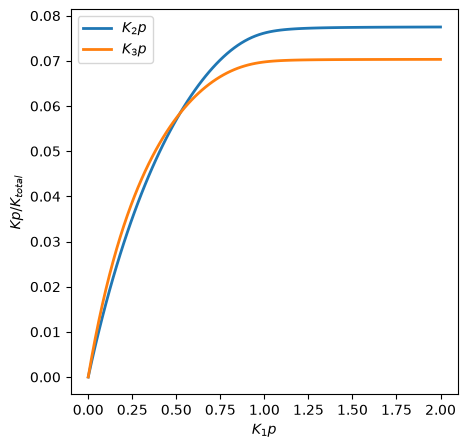

In [3]:
# STEADY-STATE responses of scaffold model for unordered binding

# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 10
k_a3 = 1
k_d = 0.1
k_p = 1
k_u = 0.1

# First, define our initial conditions
# These are going to be the same for values of 'K1p'
S = 1; K2 = 1; K2p = 0; K3 = 10; K3p = 0
SK1p = 0; SK2 = 0; SK2p = 0; SK3 = 0; SK3p = 0
SK1pK2 = 0; SK1pK2p = 0; SK1pK3 = 0; SK1pK3p = 0
SK2K3 = 0; SK2pK3 = 0; SK2K3p = 0; SK2pK3p = 0
SK1pK2K3 = 0; SK1pK2pK3 = 0; SK1pK2K3p=0; SK1pK2pK3p = 0

# Here, we define our list of K1p values:
K1p_values = np.linspace(0, 2,100)

#This will be an array that hold the steady state results
ss_results = np.empty((2,0))

for K1p in K1p_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,1000,1000)
    # We create our initial conditions for the scaffold
    states_0 = [S, K1p, K2, K2p, K3, K3p, SK1p, SK2, SK2p, SK3, SK3p,
                SK1pK2, SK1pK2p, SK1pK3, SK1pK3p, SK2K3, SK2pK3, SK2K3p,
                SK2pK3p, SK1pK2K3, SK1pK2pK3, SK1pK2K3p, SK1pK2pK3p]
    # Now, integrate the scaffold model ODEs and put the results in "solution"
    solution = odeint(scaffold_model,states_0,t)
    ss_output= np.array([[solution[999,3]/(K2)], [solution[999,5]/(K3)]])
    # Append this result to the array of our results
    ss_results = np.append(ss_results, ss_output, axis=1)

# PLOT your steady-state results
# You can save this as a JPG or PNG and insert it into your HW answer (you can google how to do that!)
# Or you can just take a screenshot. Be warned, however, the figure needs to be big enough for us to see!
plt.figure(figsize=(5, 5))
plt.plot(K1p_values,ss_results[0, :],linewidth=2, label='$K_2p$')
plt.plot(K1p_values,ss_results[1, :],linewidth=2, label='$K_3p$')
plt.xlabel('$K_1p$')
plt.ylabel('$Kp/K_{total}$')
plt.legend()
plt.show()

In [5]:
# no scaffold model
# This is the definition of our system of ODEs
def base_model(states,t):
    # Our "states" list has the state variables in the following order:
    # K2, K2p, K3, K3p
    K2 = states[0]
    K2p = states[1]
    K3 = states[2]
    K3p = states[3]
    # The above just makes it easier to relate our ODEs to the ones in the Homework text
    K2_prime = -k_a*K1p*K2 + k_u*K2p
    K2p_prime = k_a*K1p*K2 - k_u*K2p
    K3_prime = -k_a*K2p*K3 + k_u*K3p
    K3p_prime = k_a*K2p*K3 - k_u*K3p
    states_prime = [K2_prime,K2p_prime,K3_prime,K3p_prime]
    return states_prime

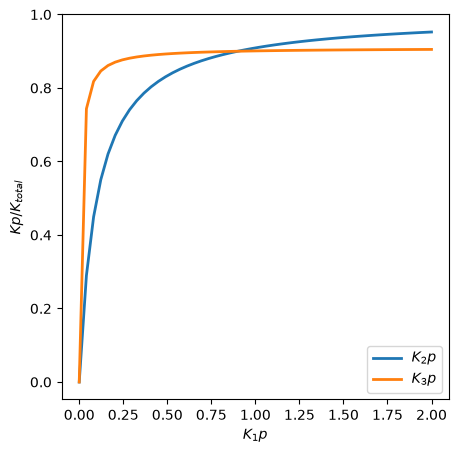

In [ ]:
# STEADY-STATE responses for no scaffold model

# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 1
k_u = 0.1

# First, define our initial conditions
# These are going to be the same for values of 'K1p'
K2 = 1
K2p = 0
K3 = 10
K3p = 0

# Here, we define our list of K1p values:
K1p_values = np.linspace(0, 2)

#This will be an array that hold the steady state results
ss_results = np.empty((2,0))

for K1p in K1p_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,1000,1000)
    # We create our initial conditions for the three-layer model
    states_0 = [K2,K2p,K3,K3p]
    # Now, integrate the three-layer model ODEs and put the results in "solution"
    solution = odeint(base_model,states_0,t)
    ss_output= np.array([[solution[999,1]/(K2)], [solution[999,3]/(K3)]])
    # Append this result to the array of our results
    ss_results = np.append(ss_results, ss_output, axis=1)

# PLOT your steady-state results
# You can save this as a JPG or PNG and insert it into your HW answer (you can google how to do that!)
# Or you can just take a screenshot. Be warned, however, the figure needs to be big enough for us to see!
plt.figure(figsize=(5, 5))
plt.plot(K1p_values,ss_results[0, :],linewidth=2, label='$K_2p$')
plt.plot(K1p_values,ss_results[1, :],linewidth=2, label='$K_3p$')
plt.xlabel('$K_1p$')
plt.ylabel('$Kp/K_{total}$')
plt.legend()
plt.show()

## Part 2: The Prozone Effect

In [7]:
# unordered scaffold model for prozone
# This is the definition of our system of ODEs for the model. Please run this cell before doing anything else in this section
def scaffold_model(states,t):
    # Our "states" list has the state variables in the following order:
    # S, K1p, K2, K2p, K3, K3p
    # SK1p, SK2, SK2p, SK3, SK3p
    # SK1pK2, SK1pK2p, SK1pK3, SK1pK3p, SK2K3, SK2pK3, SK2K3p, SK2pK3p
    # SK1pK2K3, SK1pK2pK3, SK1pK2K3p, SK1pK2pK3p

    S = states[0]; K1p = states[1]; K2 = states[2]; K2p = states[3]; K3 = states[4]; K3p = states[5]
    SK1p = states[6]; SK2 = states[7]; SK2p = states[8]; SK3 = states[9]; SK3p = states[10]
    SK1pK2 = states[11]; SK1pK2p = states[12]; SK1pK3 = states[13]; SK1pK3p = states[14]
    SK2K3 = states[15]; SK2pK3 = states[16]; SK2K3p = states[17]; SK2pK3p = states[18]
    SK1pK2K3 = states[19]; SK1pK2pK3 = states[20]; SK1pK2K3p=states[21]; SK1pK2pK3p = states[22]

    # The above just makes it easier to relate our ODEs to the ones in the Homework text
    S_prime = -k_a*S*K1p -k_a*S*K2 -k_a*S*K2p -k_a3*S*K3 -k_a3*S*K3p\
                +k_d*SK1p +k_d*SK2 +k_d*SK2p +k_d*SK3 +k_d*SK3p
    K1p_prime = -k_a*S*K1p -k_a*SK2*K1p -k_a*SK2p*K1p -k_a*SK3*K1p -k_a*SK3p*K1p\
                -k_a*SK2K3*K1p -k_a*SK2pK3*K1p -k_a*SK2K3p*K1p -k_a*SK2pK3p*K1p\
                +k_d*SK1p + k_d*SK1pK2 + k_d*SK1pK2p + k_d*SK1pK3 + k_d*SK1pK3p\
                +k_d*SK1pK2K3 + k_d*SK1pK2pK3 + k_d*SK1pK2K3p + k_d*SK1pK2pK3p
    K2_prime = -k_a*S*K2 -k_a*SK1p*K2 -k_a*SK3*K2 -k_a*SK3p*K2 -k_a*SK1pK3*K2 -k_a*SK1pK3p*K2\
                +k_d*SK2 +k_d*SK1pK2 +k_d*SK2K3 +k_d*SK2K3p +k_d*SK1pK2K3 +k_d*SK1pK2K3p +k_u*K2p
    K2p_prime = -k_a*S*K2p -k_a*SK1p*K2p -k_a*SK3*K2p -k_a*SK3p*K2p -k_a*SK1pK3*K2p -k_a*SK1pK3p*K2p\
                +k_d*SK2p +k_d*SK1pK2p +k_d*SK2pK3 +k_d*SK2pK3p +k_d*SK1pK2pK3 +k_d*SK1pK2pK3p -k_u*K2p
    K3_prime = -k_a3*S*K3 -k_a3*SK1p*K3 -k_a3*SK2*K3 -k_a3*SK2p*K3 -k_a3*SK1pK2*K3 -k_a3*SK1pK2p*K3\
                +k_d*SK3 +k_d*SK1pK3 +k_d*SK2K3 +k_d*SK2pK3 +k_d*SK1pK2K3 +k_d*SK1pK2pK3 +k_u*K3p
    K3p_prime = -k_a3*S*K3p -k_a3*SK1p*K3p -k_a3*SK2*K3p -k_a3*SK2p*K3p -k_a3*SK1pK2*K3p -k_a3*SK1pK2p*K3p\
                +k_d*SK3p +k_d*SK1pK3p +k_d*SK2K3p +k_d*SK2pK3p +k_d*SK1pK2K3p +k_d*SK1pK2pK3p -k_u*K3p

    SK1p_prime = k_a*S*K1p + k_d*SK1pK2 + k_d*SK1pK2p + k_d*SK1pK3 + k_d*SK1pK3p\
                -k_d*SK1p -k_a*SK1p*K2 -k_a*SK1p*K2p -k_a3*SK1p*K3 -k_a3*SK1p*K3p
    SK2_prime =  k_a*S*K2 + k_d*SK1pK2 + k_d*SK2K3 + k_d*SK2K3p\
                -k_d*SK2 -k_a*SK2*K1p -k_a3*SK2*K3 -k_a3*SK2*K3p +k_u*SK2p
    SK2p_prime = k_a*S*K2p + k_d*SK1pK2p + k_d*SK2pK3 + k_d*SK2pK3p\
                -k_d*SK2p -k_a*SK2p*K1p -k_a3*SK2p*K3 -k_a3*SK2p*K3p -k_u*SK2p
    SK3_prime =  k_a3*S*K3 + k_d*SK1pK3 + k_d*SK2K3 + k_d*SK2pK3\
                -k_d*SK3 -k_a*SK3*K1p -k_a*SK3*K2 -k_a*SK3*K2p +k_u*SK3p
    SK3p_prime =  k_a3*S*K3p + k_d*SK1pK3p + k_d*SK2K3p + k_d*SK2pK3p\
                -k_d*SK3p -k_a*SK3p*K1p -k_a*SK3p*K2 -k_a*SK3p*K2p -k_u*SK3p

    SK1pK2_prime =  k_a*SK1p*K2 + k_a*SK2*K1p +k_d*SK1pK2K3 +k_d*SK1pK2K3p -k_p*SK1pK2\
                    -2*k_d*SK1pK2 -k_a3*SK1pK2*K3 -k_a3*SK1pK2*K3p +k_u*SK1pK2p
    SK1pK2p_prime = k_a*SK1p*K2p + k_a*SK2p*K1p +k_d*SK1pK2pK3 +k_d*SK1pK2pK3p +k_p*SK1pK2\
                    -2*k_d*SK1pK2p -k_a3*SK1pK2p*K3 -k_a3*SK1pK2p*K3p -k_u*SK1pK2p
    SK1pK3_prime =  k_a3*SK1p*K3 + k_a*SK3*K1p +k_d*SK1pK2K3 +k_d*SK1pK2pK3\
                    -2*k_d*SK1pK3 -k_a*SK1pK3*K2 -k_a*SK1pK3*K2p +k_u*SK1pK3p
    SK1pK3p_prime =  k_a3*SK1p*K3p + k_a*SK3p*K1p +k_d*SK1pK2K3p +k_d*SK1pK2pK3p\
                    -2*k_d*SK1pK3p -k_a*SK1pK3p*K2 -k_a*SK1pK3p*K2p -k_u*SK1pK3p
    SK2K3_prime =  k_a3*SK2*K3 + k_a*SK3*K2 +k_d*SK1pK2K3 +k_u*SK2pK3 +k_u*SK2K3p\
                    -2*k_d*SK2K3 -k_a*SK2K3*K1p
    SK2pK3_prime =  k_a3*SK2p*K3 + k_a*SK3*K2p +k_d*SK1pK2pK3 +k_u*SK2pK3p -k_u*SK2pK3\
                    -2*k_d*SK2pK3 -k_a*SK2pK3*K1p - k_p*SK2pK3
    SK2K3p_prime =  k_a3*SK2*K3p + k_a*SK3p*K2 +k_d*SK1pK2K3p +k_u*SK2pK3p -k_u*SK2K3p\
                    -2*k_d*SK2K3p -k_a*SK2K3p*K1p
    SK2pK3p_prime =  k_a3*SK2p*K3p + k_a*SK3p*K2p +k_d*SK1pK2pK3p -2*k_u*SK2pK3p\
                    -2*k_d*SK2pK3p -k_a*SK2pK3p*K1p + k_p*SK2pK3

    SK1pK2K3_prime = k_a3*SK1pK2*K3 + k_a*SK1pK3*K2 + k_a*SK2K3*K1p\
                    -3*k_d*SK1pK2K3 - k_p*SK1pK2K3 + k_u*SK1pK2pK3 + k_u*SK1pK2K3p
    SK1pK2pK3_prime = k_a3*SK1pK2p*K3 + k_a*SK1pK3*K2p + k_a*SK2pK3*K1p + k_p*SK1pK2K3 +k_u*SK1pK2pK3p\
                    -3*k_d*SK1pK2pK3  -k_p*SK1pK2pK3 - k_u*SK1pK2pK3
    SK1pK2K3p_prime = k_a3*SK1pK2*K3p + k_a*SK1pK3p*K2 + k_a*SK2K3p*K1p +k_u*SK1pK2pK3p\
                    -3*k_d*SK1pK2K3p -k_p*SK1pK2K3p - k_u*SK1pK2K3p
    SK1pK2pK3p_prime = k_a3*SK1pK2p*K3p + k_a*SK1pK3p*K2p + k_a*SK2pK3p*K1p\
                    -3*k_d*SK1pK2pK3p -2*k_u*SK1pK2pK3p +k_p*SK1pK2pK3 + k_p*SK1pK2K3p

    states_prime = [S_prime, K1p_prime, K2_prime, K2p_prime, K3_prime, K3p_prime,
                    SK1p_prime, SK2_prime, SK2p_prime, SK3_prime, SK3p_prime,
                    SK1pK2_prime, SK1pK2p_prime, SK1pK3_prime, SK1pK3p_prime,
                    SK2K3_prime, SK2pK3_prime, SK2K3p_prime, SK2pK3p_prime,
                    SK1pK2K3_prime, SK1pK2pK3_prime, SK1pK2K3p_prime, SK1pK2pK3p_prime]

    return states_prime

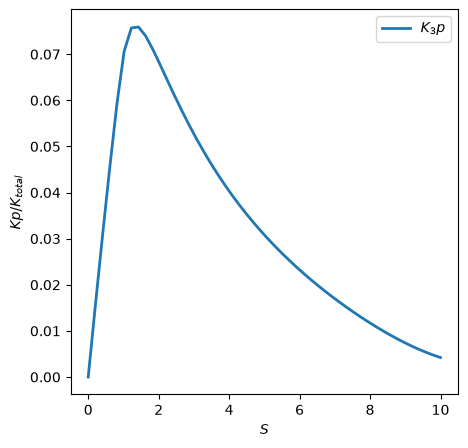

In [9]:

#Steady state
# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 10
k_a3 = 1
k_d = 0.1
k_p = 1
k_u = 0.1

# First, define our initial conditions
# These are going to be the same for values of 's'
K1p = 1; K2 = 1; K2p = 0; K3 = 10; K3p = 0

# Here, we define our list of S values:
S_values = np.linspace(0, 10)

#This will be an array that hold the steady state results
ss_results = []

for S in S_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,1000,1000)
    # We create our initial conditions for the scaffold
    states_0 = [S, K1p, K2, K2p, K3, K3p] + [0.0] * 17
    # Now, integrate the scaffold model ODEs and put the results in "solution"
    solution = odeint(scaffold_model,states_0,t)
    ss_output= solution[999, 5]/(K3)
    # Append this result to the array of our results
    ss_results = np.append(ss_results, ss_output)

# PLOT your steady-state results
# You can save this as a JPG or PNG and insert it into your HW answer (you can google how to do that!)
# Or you can just take a screenshot. Be warned, however, the figure needs to be big enough for us to see!
plt.figure(figsize=(5, 5))
plt.plot(S_values,ss_results,linewidth=2, label='$K_3p$')
plt.xlabel('$S$')
plt.ylabel('$Kp/K_{total}$')
plt.legend()
plt.show()

In [10]:
peak_index = np.argmax(ss_results)
print(f"Scaffold concentration at maximum response: {S_values[peak_index]:.2f} µM")

Scaffold concentration at maximum response: 1.43 µM


# Part 3 Ordered Binding

In [11]:
# Ordered Binding
# This is the definition of our system of ODEs for the model
def ordered_model(states,t):
    # Our "states" list has the state variables in the following order:
    # S, K1p, K2, K2p, K3, K3p, SK1p, SK1pK2, SK1pK2p, SK1pK2pK3, SK1pK2pK3p

    S = states[0]; K1p = states[1]; K2 = states[2]; K2p = states[3]; K3 = states[4]; K3p = states[5]
    SK1p = states[6]; SK1pK2 = states[7]; SK1pK2p = states[8]; SK1pK2pK3 = states[9]; SK1pK2pK3p = states[10]

    # The above just makes it easier to relate our ODEs to the ones in the Homework text, Please use these terms when creating
    # the change equationss

    ### fill in your change equations
    S = states[0]
    K1p = states[1]
    K2 = states[2]
    K2p = states[3]
    K3 = states[4]
    K3p = states[5]
    SK1p = states[6]
    SK1pK2 = states[7]
    SK1pK2p = states[8]
    SK1pK2pK3 = states[9]
    SK1pK2pK3p = states[10]

    S_prime = -k_a*S*K1p + k_d*SK1p

    K1p_prime = -k_a*S*K1p + k_d*SK1p

    K2_prime = -k_a*SK1p*K2 + k_d*SK1pK2 + k_u*K2p

    K2p_prime = -k_a*SK1p*K2p + k_d*SK1pK2p - k_u*K2p
    
    K3_prime = -k_a3*SK1pK2p*K3 + k_d*SK1pK2pK3 + k_u*K3p

    K3p_prime = -k_a3*SK1pK2p*K3p + k_d*SK1pK2pK3p - k_u*K3p

    SK1p_prime = (
        k_a*S*K1p - k_d*SK1p
        - k_a*SK1p*K2 - k_a*SK1p*K2p
        + k_d*SK1pK2 + k_d*SK1pK2p
    )

    SK1pK2_prime = (
        k_a*SK1p*K2 - k_d*SK1pK2
        - k_p*SK1pK2 + k_u*SK1pK2p
    )

    SK1pK2p_prime = (
        k_a*SK1p*K2p - k_d*SK1pK2p
        + k_p*SK1pK2 - k_u*SK1pK2p
        - k_a3*SK1pK2p*K3 - k_a3*SK1pK2p*K3p
        + k_d*SK1pK2pK3 + k_d*SK1pK2pK3p
    )

    SK1pK2pK3_prime = (
        k_a3*SK1pK2p*K3 - k_d*SK1pK2pK3
        - k_p*SK1pK2pK3 + k_u*SK1pK2pK3p
    )

    SK1pK2pK3p_prime = (
        k_a3*SK1pK2p*K3p - k_d*SK1pK2pK3p
        + k_p*SK1pK2pK3 - k_u*SK1pK2pK3p
    )

    states_prime = [S_prime, K1p_prime, K2_prime, K2p_prime, K3_prime, K3p_prime,
                    SK1p_prime, SK1pK2_prime, SK1pK2p_prime, SK1pK2pK3_prime, SK1pK2pK3p_prime]

    return states_prime

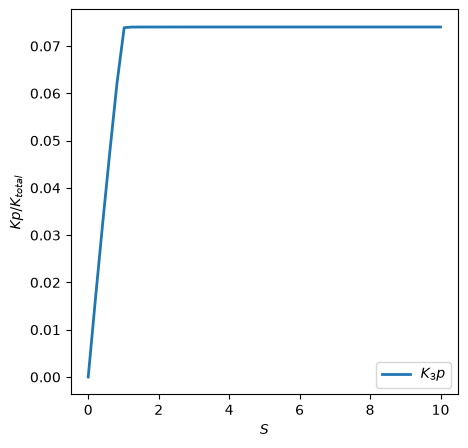

In [15]:
# STEADY-STATE responses for ordered bindinng

# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 10
k_a3 = 1
k_d = 0.1
k_p = 1
k_u = 0.1

# First, define our initial conditions
# These are going to be the same for values of 'S'
S = 1; K1p = 1; K2 = 1; K2p = 0; K3 = 10; K3p = 0

# Here, we define our list of S values:
S_values = np.linspace(0, 10)

#This will be an array that hold the steady state results
ss_results = []

for S in S_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,1000,1000)
    # We create our initial conditions for the scaffold
    states_0 = [S, K1p, K2, K2p, K3, K3p] + [0.0] * 5
    # Now, integrate the scaffold model ODEs and put the results in "solution"
    solution = odeint(ordered_model,states_0,t)
    ss_output= ( solution[-1, 5]/K3 )
    # Append this result to the array of our results
    ss_results = np.append(ss_results, ss_output)

# PLOT your steady-state results
# You can save this as a JPG or PNG and insert it into your HW answer (you can google how to do that!)
# Or you can just take a screenshot. Be warned, however, the figure needs to be big enough for us to see!
plt.figure(figsize=(5, 5))
plt.plot(S_values,ss_results,linewidth=2, label='$K_3p$')
plt.xlabel('$S$')
plt.ylabel('$Kp/K_{total}$')
plt.legend()
plt.show()

## Part 4 Multisite Phosphorylation

In [16]:
#This defines our multt site phosphorylation model. Please run this cell before generating any graphs
def multisite4(states,t,k_a,k_u,K1star):
    S0 = states[0]
    S1 = states[1]
    S2 = states[2]
    S3 = states[3]
    S4 = states[4]
    #The above just makes it easier to relate our ODEs to the ones in the Homework text, Please use these terms when
    #creating your ODEs
    # k_a is you assocation constation while k_u is your dissoctiation constant. K1star is the activated kinase that is our input signal
    # Fill in your ODE's below


    S0_prime = -k_a*K1star*S0 + k_u*S1
    S1_prime = (
        k_a*K1star*S0 - k_a*K1star*S1 - k_u*S1 + k_u*S2
    )
    S2_prime = (
        k_a*K1star*S1 - k_a*K1star*S2 - k_u*S2 + k_u*S3
    )
    S3_prime = (
        k_a*K1star*S2 - k_a*K1star*S3 - k_u*S3 + k_u*S4
    )
    S4_prime = k_a*K1star*S3 - k_u*S4 


    #
    states_prime = [S0_prime,S1_prime,S2_prime,S3_prime,S4_prime]
    return states_prime


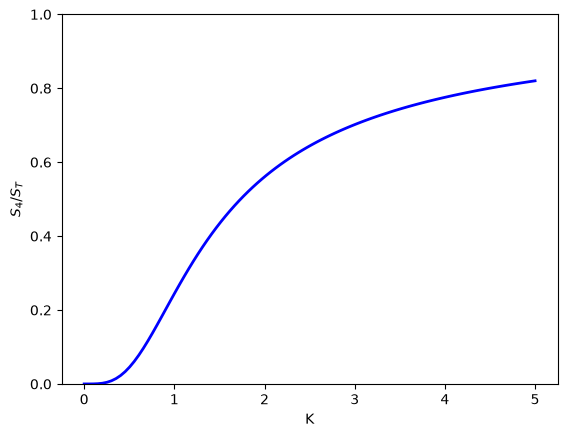

In [ ]:
# Steady State Simulation: This is where we find the long term behavior.
#Our parameters for the model
# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 10
k_u = 1
#  Our static initial conditions
# These are going to be the same for values of 'K1star'
S0_0 = 0.1
S1_0 = 0
S2_0 = 0
S3_0 = 0
S4_0 = 0

# Here, we define our list of K1star values (aka our initial constats):
K_values = np.linspace(0, 5,100)

#This will be an array that hold the steady state results
ss_results = []

for K in K_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,20000000,2000)
    # We create our initial conditions for the three-layer model
    states_0 = [S0_0,S1_0,S2_0,S3_0,S4_0]
    # Now, integrate the three-layer model ODEs and put the results in "solution_3"
    solution = odeint(multisite4,states_0,t,(k_a,k_u,K))
    # Now, calculate our output, which remember from lecture is S*/S_t
    # (the concentration of modified substrate divided by the total substrate concentration)
    # Note that, since total substrate is conserved, S_T is just equal to S_0
    # Note that we are taking the last time point. Since there are 2,000 time points
    # The index of the last time point is 1,999
    norm_S4 = solution[1999,4]/S0_0
    # Append this result to the vector of our results
    ss_results.append(norm_S4)
plt.plot(K_values,ss_results,'b-',linewidth=2)
plt.xlabel('K')
plt.ylabel('$S_4$/$S_T$')
plt.ylim((0,1))
plt.show()

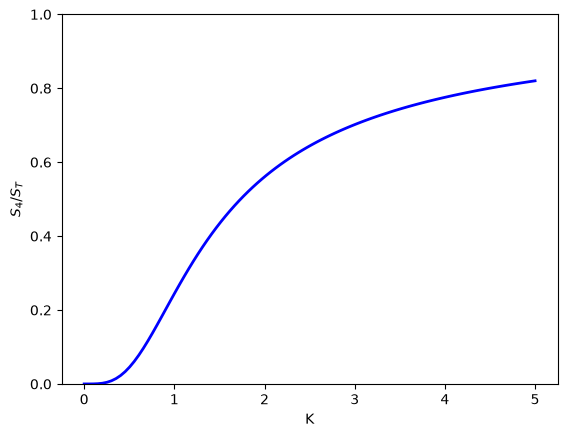

In [21]:
# Steady State Simulation: This is where we find the long term behavior.
#Our parameters for the model
# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 10
k_u = 9
#  Our static initial conditions
# These are going to be the same for values of 'K1star'
S0_0 = 0.1
S1_0 = 0
S2_0 = 0
S3_0 = 0
S4_0 = 0

# Here, we define our list of K1star values (aka our initial constats):
K_values = np.linspace(0, 5,100)

#This will be an array that hold the steady state results
ss_results = []

for K in K_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,20000000,2000)
    # We create our initial conditions for the three-layer model
    states_0 = [S0_0,S1_0,S2_0,S3_0,S4_0]
    # Now, integrate the three-layer model ODEs and put the results in "solution_3"
    solution = odeint(multisite4,states_0,t,(k_a,k_u,K))
    # Now, calculate our output, which remember from lecture is S*/S_t
    # (the concentration of modified substrate divided by the total substrate concentration)
    # Note that, since total substrate is conserved, S_T is just equal to S_0
    # Note that we are taking the last time point. Since there are 2,000 time points
    # The index of the last time point is 1,999
    norm_S4 = solution[1999,4]/S0_0
    # Append this result to the vector of our results
    ss_results.append(norm_S4)
plt.plot(K_values,ss_results,'b-',linewidth=2)
plt.xlabel('K')
plt.ylabel('$S_4$/$S_T$')
plt.ylim((0,1))
plt.show()